In [85]:
import os

os.environ["MPL_IGNORE_SYSTEM_FONTS"] = "1"

import matplotlib.pyplot as plt
import functions
import numpy as np

print("Imports successful!")

Imports successful!


In [106]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 
import pickle

from matplotlib import pyplot as plt
from scipy.optimize import least_squares
from random import randint
from itertools import product

import importlib
import functions
import scattering_model
import differential_evolution_routine
import window_generation

importlib.reload(functions)
importlib.reload(scattering_model)
importlib.reload(differential_evolution_routine)
importlib.reload(window_generation)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<module 'window_generation' from '/Users/peytaguo/Desktop/ASC/Nucelar Resonance Analysis /window_generation.py'>

In [3]:
ne_amu = 19.9869544
a_amu = 4.001506179129

mg_amu = 23.9784588
uc2 = 931.494 #MeV

energy_threshold = (ne_amu + a_amu - mg_amu)*uc2
print(energy_threshold)

9.316597247987401


In [4]:
sigma = np.load("data/peyta_sigma1.npy")
dsigma = np.load("data/peyta_dsigma1.npy")
theta_cm = np.load("data/peyta_theta_cm1.npy")
ke_cm = np.load("data/peyta_ke_cm1.npy")

rounded_theta_cm = np.round(theta_cm, 1)
rounded_theta_cm[rounded_theta_cm == 53.2] = 53.1
rounded_theta_cm[rounded_theta_cm == 143.2] = 143.1
rounded_theta_cm[rounded_theta_cm == 155.7] = 155.8

print( np.unique( rounded_theta_cm ) )
print(len(np.unique(rounded_theta_cm)))

[ 53.1  58.8  70.   75.5  86.2  91.4 101.6 106.5 116.2 125.5 130.  138.8
 143.1 155.8 163.9 168. ]
16


In [5]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma, 9.31)
#functions.visualise_all_peaks(all_cs)

In [6]:
clusters_dp_chosen = functions.get_clusters_dp(all_cs, 0.001, 0.005)

In [7]:
clusters_dp_chosen[0]

[np.float64(13.32186782827972),
 [[58.8, np.float64(13.315620272331726), np.float64(0.48017776796147543)],
  [53.1, np.float64(13.328115384227713), np.float64(0.696244297387564)]]]

In [8]:
cluster_widths = functions.get_cluster_widths(clusters_dp_chosen)

In [ ]:
#functions.get_dp_clusters_info(clusters_dp_chosen)

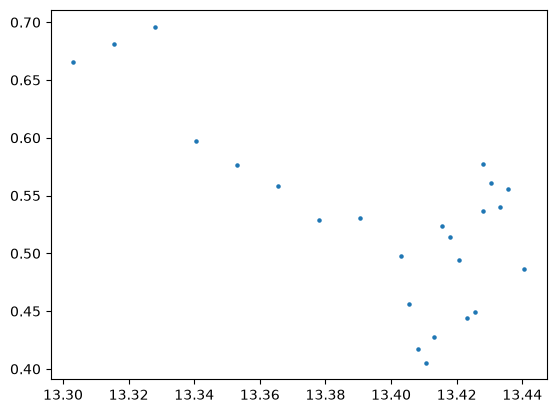

In [9]:
angles = list(all_cs.keys())

#all_cs[angles[0]].keys() -> 'ke', 'sigma', 'dsigma'

sigma_531 = all_cs[angles[0]]['sigma']
ke_531 = all_cs[angles[0]]['ke']

E_min, E_max = 13, 13.45

mask = (ke_531 >= E_min) & (ke_531 <= E_max)

E_window = ke_531[mask]
sigma_window = sigma_531[mask]

plt.scatter(
    E_window, 
    sigma_window,
    s=5
)
plt.show()

In [10]:
cluster_energies = [cluster[0] for cluster in clusters_dp_chosen]
cluster_widths = functions.get_cluster_widths(clusters_dp_chosen)

initial_parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

print(cluster_energies)

[np.float64(13.32186782827972), np.float64(13.379647365167385), np.float64(13.420724960967716), np.float64(13.478503549358422), np.float64(13.554854287229828), np.float64(13.636278844758236), np.float64(13.68791759034153), np.float64(13.731515116522399), np.float64(13.779079089074513), np.float64(13.824890878203005), np.float64(13.863283520137786), np.float64(13.908262928283293), np.float64(14.02283366705244), np.float64(14.059876681221004), np.float64(14.095513128862724), np.float64(14.144741357771649), np.float64(14.170529678049867), np.float64(14.255868680681997), np.float64(14.331302842044678), np.float64(14.390549114451925), np.float64(14.463505344036344), np.float64(14.497741458028996), np.float64(14.548318080561536), np.float64(14.62324668213953), np.float64(14.6578396757273), np.float64(14.69437965149989), np.float64(14.757488310032965), np.float64(14.84187951342079), np.float64(14.88494707406901), np.float64(14.924782404250218), np.float64(14.99110263791823), np.float64(15.064

In [11]:
window = scattering_model.get_window_cs(all_cs, E_min, E_max)

number_of_resonances = int((len(initial_parameters) - 32)/5)

angular_momenta = [randint(0,5) for _ in range(number_of_resonances)]

intial_parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

lower_bound, upper_bound = scattering_model.get_bounds(E_min, E_max, cluster_energies)

initial_res = scattering_model.get_residual(intial_parameters, angular_momenta, window)

#print(initial_res)

In [12]:
print("Initial parameters:", np.shape(initial_parameters))
print("Lower bounds:", np.shape(lower_bound))
print("Upper bounds:", np.shape(upper_bound))

Initial parameters: (137,)
Lower bounds: (137,)
Upper bounds: (137,)


In [ ]:
fits = []

combinations = list(product(range(6), repeat=number_of_resonances))
total = len(combinations)

for i, angular_momenta in enumerate(combinations, start=1):
    fit = least_squares(
    scattering_model.get_residual,
    x0 = intial_parameters,
    args = (angular_momenta, window),
    bounds = (lower_bound, upper_bound),
    max_nfev = 200,
    verbose = 1
)
    fits.append((fit, angular_momenta))

    print(
    f"\rProgress: {100*i/total:.1f}% "
    f"({i}/{total})",
    end="",
    flush=True
    )
    
fits.sort(key=lambda fit: fit[0].cost)
top_fits = fits[:10]



In [ ]:
import pickle

with open("top_10_fits.pkl", "wb") as f:
    pickle.dump(top_fits, f)

In [ ]:
refined_fits = []

for i, (fit, angular_momenta) in enumerate(top_fits, start=1):

    fit = least_squares(
        scattering_model.get_residual,
        x0=fit.x,
        args=(angular_momenta, window),
        bounds=(lower_bound, upper_bound),
        max_nfev=3000,
        verbose=1
    )

    refined_fits.append(
        (fit.cost, angular_momenta, fit.x)
    )

    print(f"\r {100*i/len(top_fits):.1f}% complete",
          end="", flush=True)

# Rank by refined cost
refined_fits.sort(key=lambda fit: fit[0])

In [ ]:
# Save all 10 refined results
with open("top_10_refined_fits.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

In [ ]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

In [ ]:
print(best_angular_momenta)
print(best_params)

In [12]:
scattering_model.get_fit_visual(window, best_params, best_angular_momenta)
print(best_angular_momenta)

NameError: name 'best_params' is not defined

In [13]:
clusters = scattering_model.get_window_clusters(cluster_energies)
clusters = scattering_model.merge_clusters(clusters)

In [15]:
windows = scattering_model.get_windows(all_cs, clusters)

In [16]:
for cluster in clusters:
    print(len(cluster))

print(len(clusters))

2
2
2
2
1
2
1
3
2
2
1
2
1
3
2
2
2
2
1
2
2
2
2
2
2
2
1
2
2
2
2
2
2
2
2
2
2
2
2
2
3
2
2
1
2
2
2
2
48


In [17]:
for cluster in clusters:
    print(len(cluster))

current_window = windows[0]
angle = list(current_window.keys())[0]
print(current_window[angle]["E_min"])
print(current_window[angle]["E_max"])

2
2
2
2
1
2
1
3
2
2
1
2
1
3
2
2
2
2
1
2
2
2
2
2
2
2
1
2
2
2
2
2
2
2
2
2
2
2
2
2
3
2
2
1
2
2
2
2
13.303124963035371
13.40018616306755


In [18]:
first_window = windows[0]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(first_window, cluster_energies, cluster_widths)

with open("top_fits_w1.pkl", "wb") as f:
    pickle.dump(fits, f)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.1597e+11, final cost 5.6743e+03, first-order optimality 6.53e+02.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.6123e+11, final cost 2.2567e+03, first-order optimality 1.53e+03.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.5302e+11, final cost 4.6203e+05, first-order optimality 9.63e+05.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.0461e+11, final cost 8.5948e+03, first-order optimality 3.64e+03.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.7150e+11, final cost 6.6286e+03, first-order optimality 4.59e+03.
Progress: 13.9% (5/36)The maxim

In [19]:
refined_fits = scattering_model.fitting_routine_2(fits, first_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w1.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

`xtol` termination condition is satisfied.
Function evaluations 82, initial cost 2.2567e+03, final cost 1.6252e+03, first-order optimality 1.41e+02.
 10.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 2.7333e+03, final cost 2.3721e+03, first-order optimality 9.72e+02.
 20.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.2883e+03, final cost 3.2039e+03, first-order optimality 7.67e+02.
 30.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.4815e+03, final cost 3.3686e+03, first-order optimality 5.39e+02.
 40.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.4878e+03, final cost 3.4234e+03, first-order optimality 3.31e+02.
 50.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.5244e+03, final cost 3

Resonance 1: E_r = 13.311756 MeV, l = 0, Gamma = 0.428375 MeV
Resonance 2: E_r = 13.359647 MeV, l = 1, Gamma = 0.085664 MeV


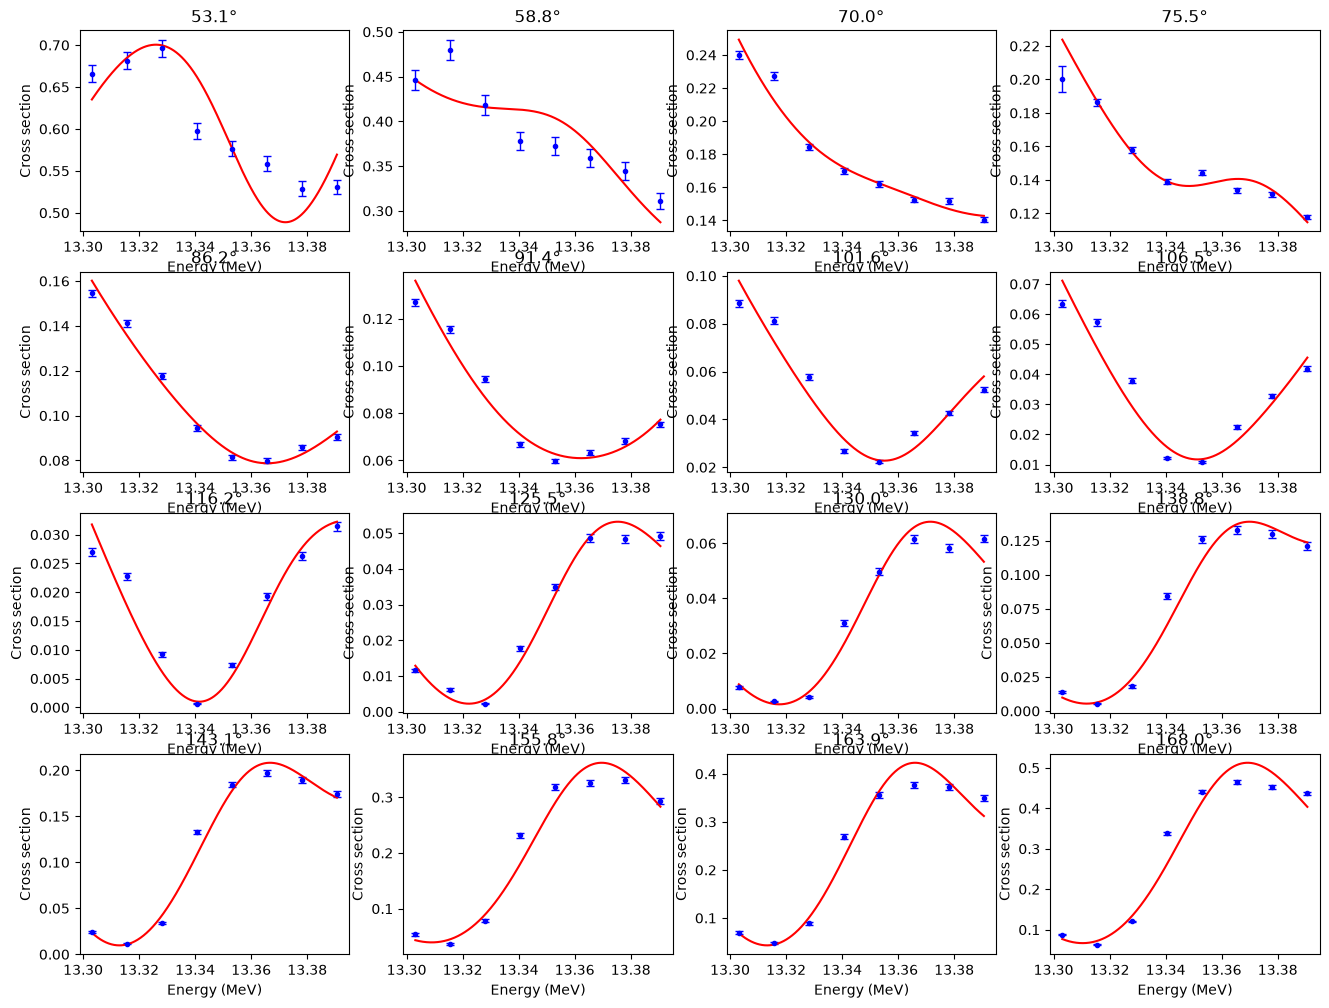

In [20]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(first_window, best_params, best_angular_momenta)

In [21]:
second_window = windows[1]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(second_window, cluster_energies, cluster_widths)

with open("top_fits_w2.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, second_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w2.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.8536e+11, final cost 3.6186e+04, first-order optimality 1.37e+02.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.4916e+11, final cost 1.8914e+05, first-order optimality 5.82e+05.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.9311e+11, final cost 4.2801e+04, first-order optimality 1.38e+04.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.3800e+11, final cost 1.1345e+05, first-order optimality 3.01e+05.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.2917e+11, final cost 8.2310e+04, first-order optimality 2.67e+05.
Progress: 13.9% (5/36)The maxim

## Assuming two resonances in the window according to previous clustering:
(The fit seems to be missing a resonance)

Resonance 1: E_r = 13.439379 MeV, l = 2, Gamma = 0.085683 MeV
Resonance 2: E_r = 13.458504 MeV, l = 0, Gamma = 0.085299 MeV


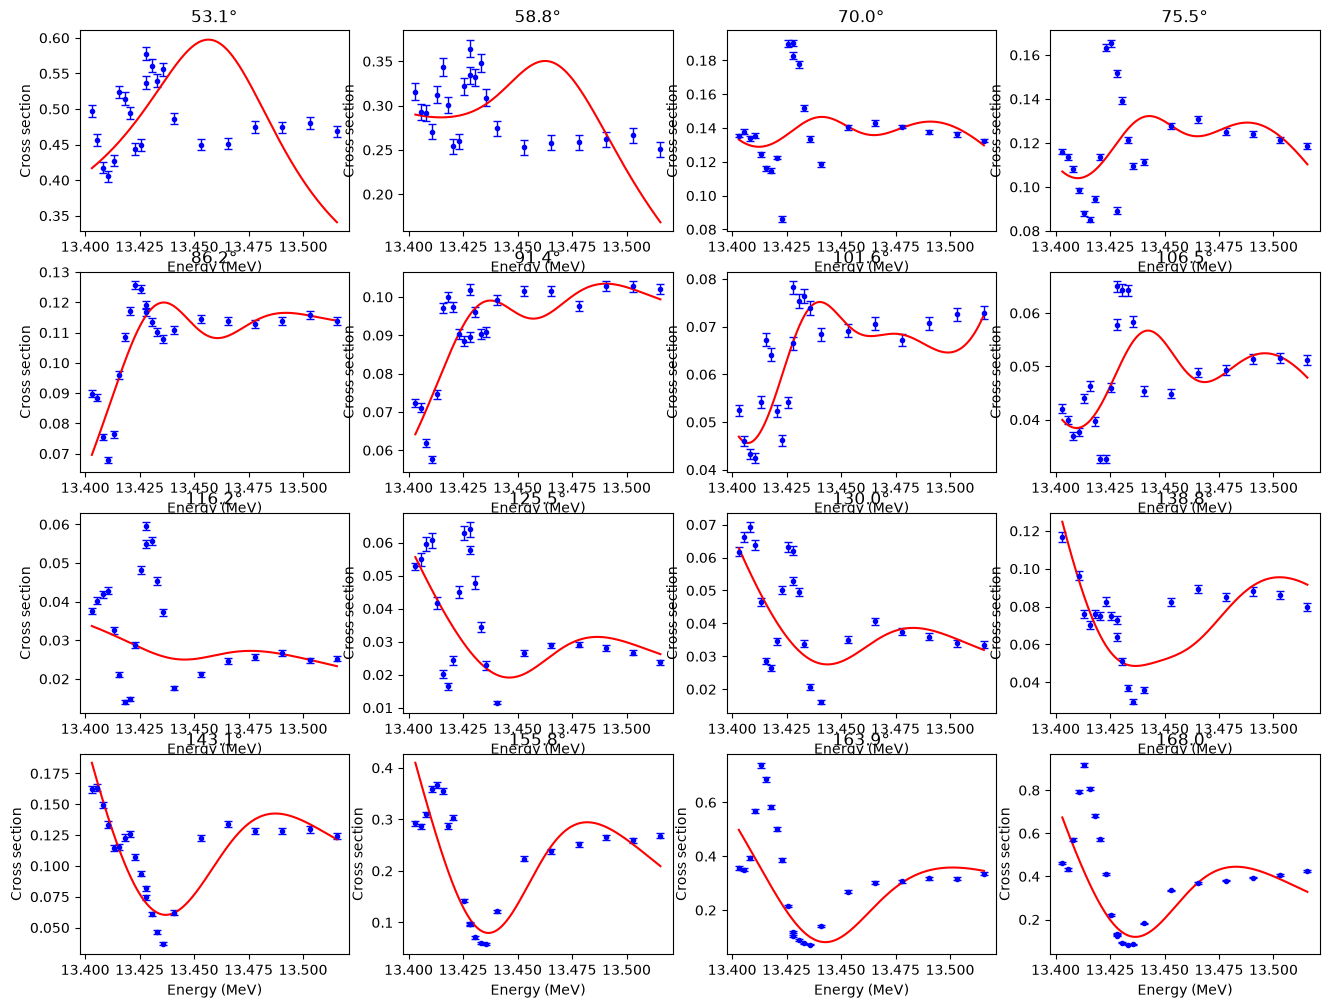

(2, 0)


In [22]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(second_window, best_params, best_angular_momenta)
print(best_angular_momenta)

## Introducing an additional resonance:

Initial parameters: (137,)
Lower bounds: (137,)
Upper bounds: (137,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.5401e+11, final cost 4.3260e+04, first-order optimality 4.85e+04.
Progress: 0.5% (1/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.6183e+11, final cost 3.9023e+04, first-order optimality 5.53e+03.
Progress: 0.9% (2/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.6797e+11, final cost 4.5076e+04, first-order optimality 2.55e+03.
Progress: 1.4% (3/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.5340e+11, final cost 3.9056e+04, first-order optimality 2.72e+03.
Progress: 1.9% (4/216)`xtol` termination condition is satisfied.
Function evaluations 67, initial cost 4.5780e+11, final cost 7.2072e+04, first-order optimality 5.13e+08.
Progress: 2.3% (5/216)The maximum number o

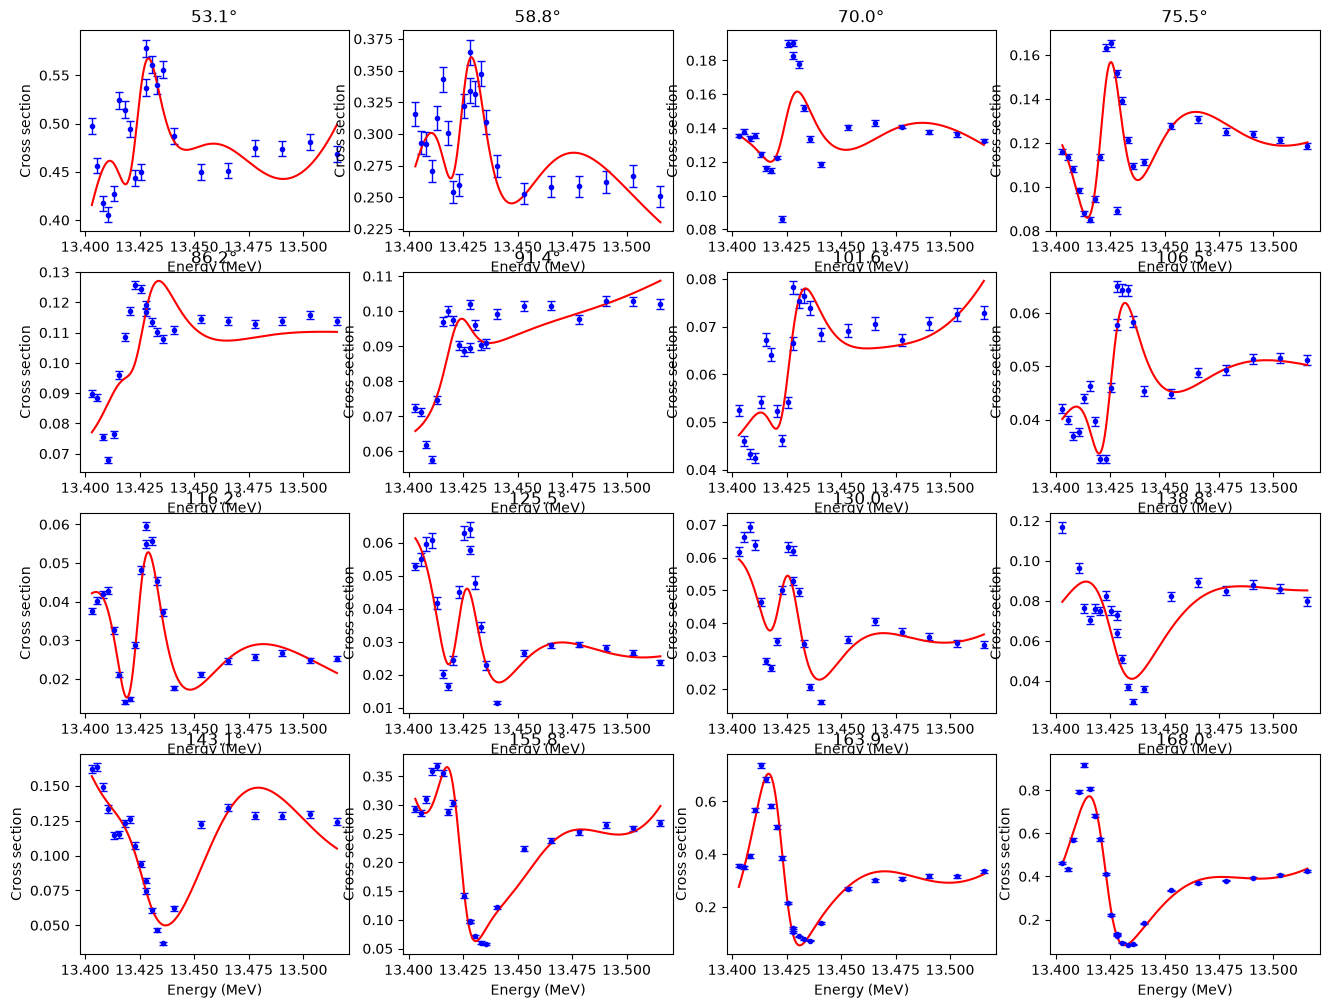

In [23]:
test_energies = np.append(cluster_energies, 13.41)
test_widths = np.append(cluster_widths, 0.005)

test_fits, test_lower_bound, test_upper_bound = scattering_model.fitting_routine_1(
    second_window,
    test_energies,
    test_widths
)

test_refined_fits = scattering_model.fitting_routine_2(test_fits, second_window, test_lower_bound, test_upper_bound)

test_best_fit_cost, test_best_angular_momenta, test_best_params = test_refined_fits[0]

scattering_model.get_fit_visual(second_window, test_best_params, test_best_angular_momenta)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3078e+11, final cost 2.4588e+03, first-order optimality 1.16e+04.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3522e+11, final cost 3.9990e+03, first-order optimality 2.51e+03.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3419e+11, final cost 3.3217e+03, first-order optimality 9.36e+03.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.2883e+11, final cost 2.0976e+03, first-order optimality 7.38e+01.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3679e+11, final cost 2.8884e+03, first-order optimality 4.36e+03.
Progress: 13.9% (5/36)The maxim

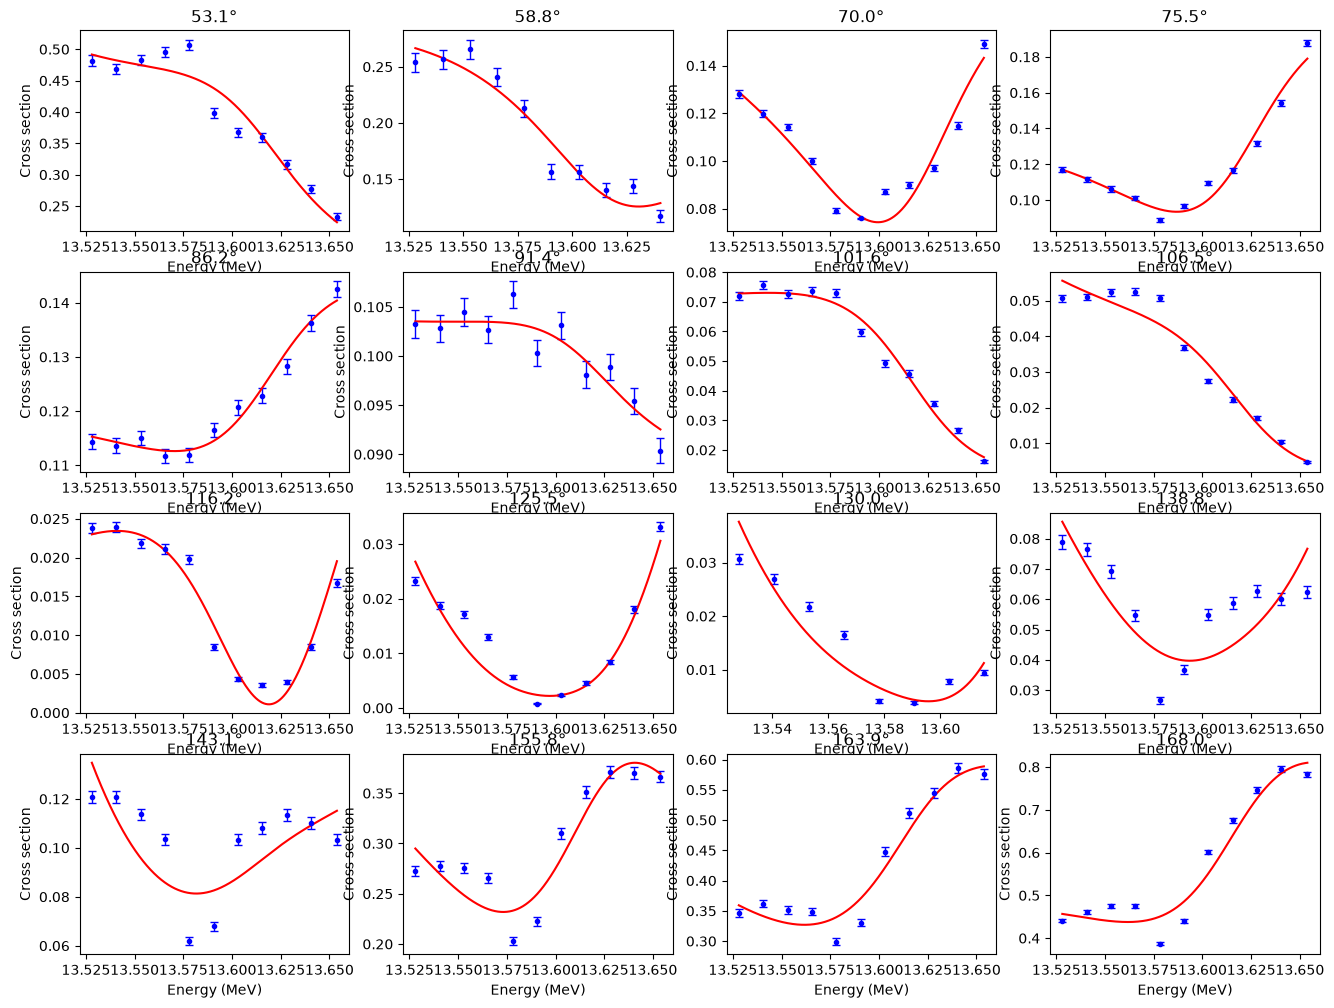

(1, 3)


In [24]:
third_window = windows[2]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(third_window, cluster_energies, cluster_widths)

with open("top_fits_w3.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, third_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w3.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(third_window, best_params, best_angular_momenta)
print(best_angular_momenta)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.3009e+11, final cost 9.8474e+03, first-order optimality 9.33e+03.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.4378e+11, final cost 1.0577e+04, first-order optimality 2.68e+04.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.4963e+11, final cost 1.8387e+04, first-order optimality 4.13e+04.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.3883e+11, final cost 8.9931e+03, first-order optimality 9.50e+03.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.4074e+11, final cost 6.8899e+04, first-order optimality 8.36e+04.
Progress: 13.9% (5/36)The maxim

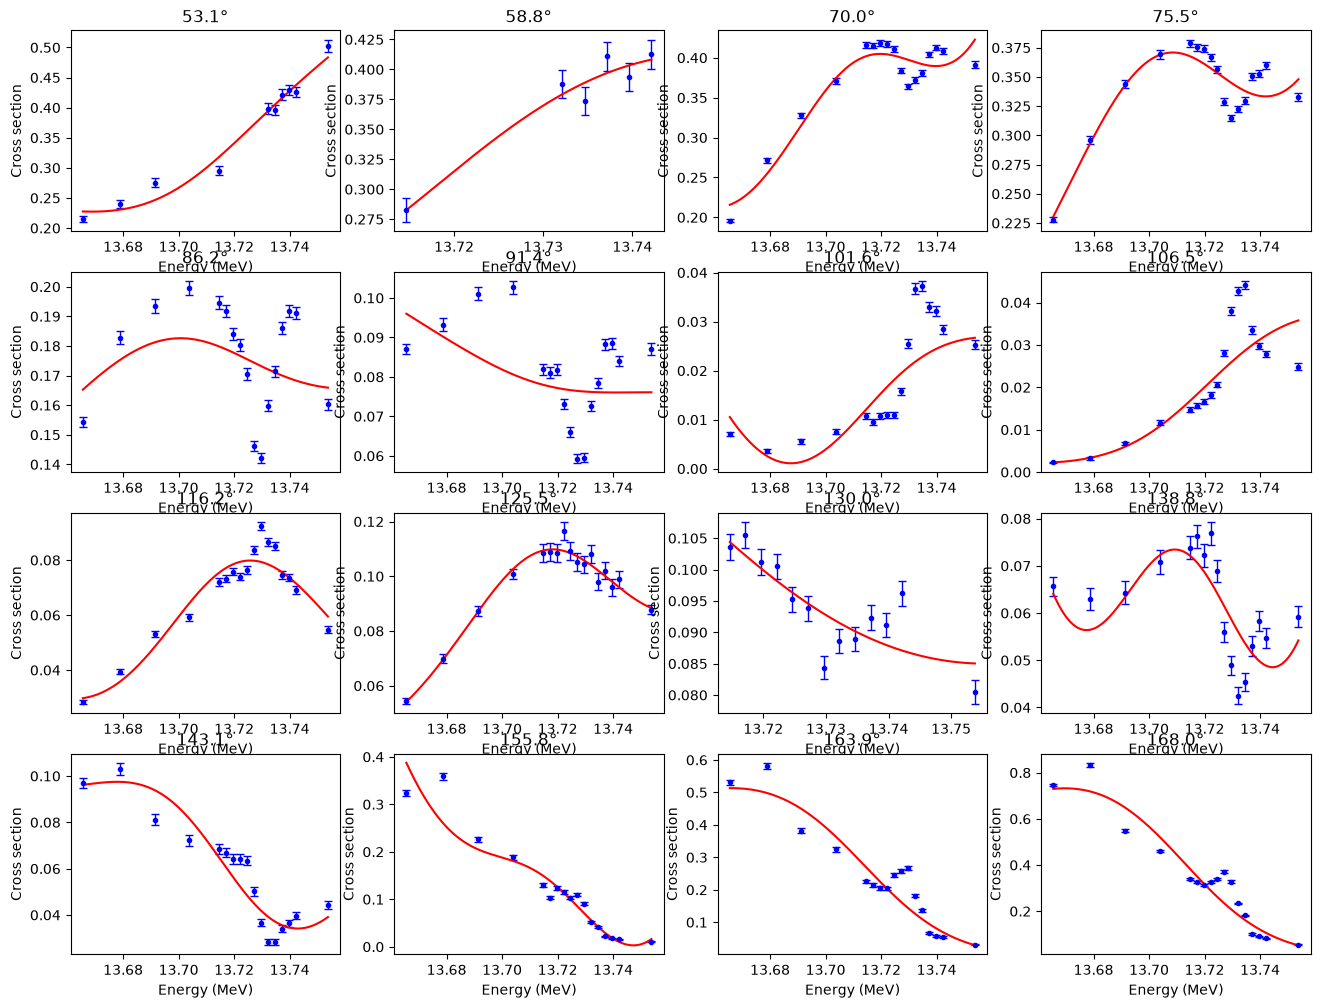

(1, 1)


In [25]:
fourth_window = windows[3]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(fourth_window, cluster_energies, cluster_widths)

with open("top_fits_w3.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, fourth_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w3.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(fourth_window, best_params, best_angular_momenta)
print(best_angular_momenta)

In [31]:
angular_momenta = (0, 1)

result, bounds = differential_evolution_routine.de_fitting_routine(
    first_window,
    cluster_energies,
    angular_momenta,
    m_cap=10,
    c_cap=10,
    maxiter=1000
)

differential_evolution step 1: f(x)= 6347963990.990068
differential_evolution step 2: f(x)= 5522198184.50517
differential_evolution step 3: f(x)= 3564450773.4664307
differential_evolution step 4: f(x)= 1575636270.042467
differential_evolution step 5: f(x)= 1575636270.042467
differential_evolution step 6: f(x)= 1575636270.042467
differential_evolution step 7: f(x)= 1153656889.050335
differential_evolution step 8: f(x)= 1079953507.0722084
differential_evolution step 9: f(x)= 561998208.2599351
differential_evolution step 10: f(x)= 561998208.2599351
differential_evolution step 11: f(x)= 200036395.70451266
differential_evolution step 12: f(x)= 200036395.70451266
differential_evolution step 13: f(x)= 134639742.23032567
differential_evolution step 14: f(x)= 70920703.78705654
differential_evolution step 15: f(x)= 70920703.78705654
differential_evolution step 16: f(x)= 70920703.78705654
differential_evolution step 17: f(x)= 39231142.31967068
differential_evolution step 18: f(x)= 39231142.319670

## Fixed Angular momentum (DE)

Resonance 1: E_r = 13.317302 MeV, l = 0, Gamma = 0.817728 MeV ratio = 0.008495
Resonance 2: E_r = 13.360778 MeV, l = 1, Gamma = 0.018485 MeV ratio = 0.052119


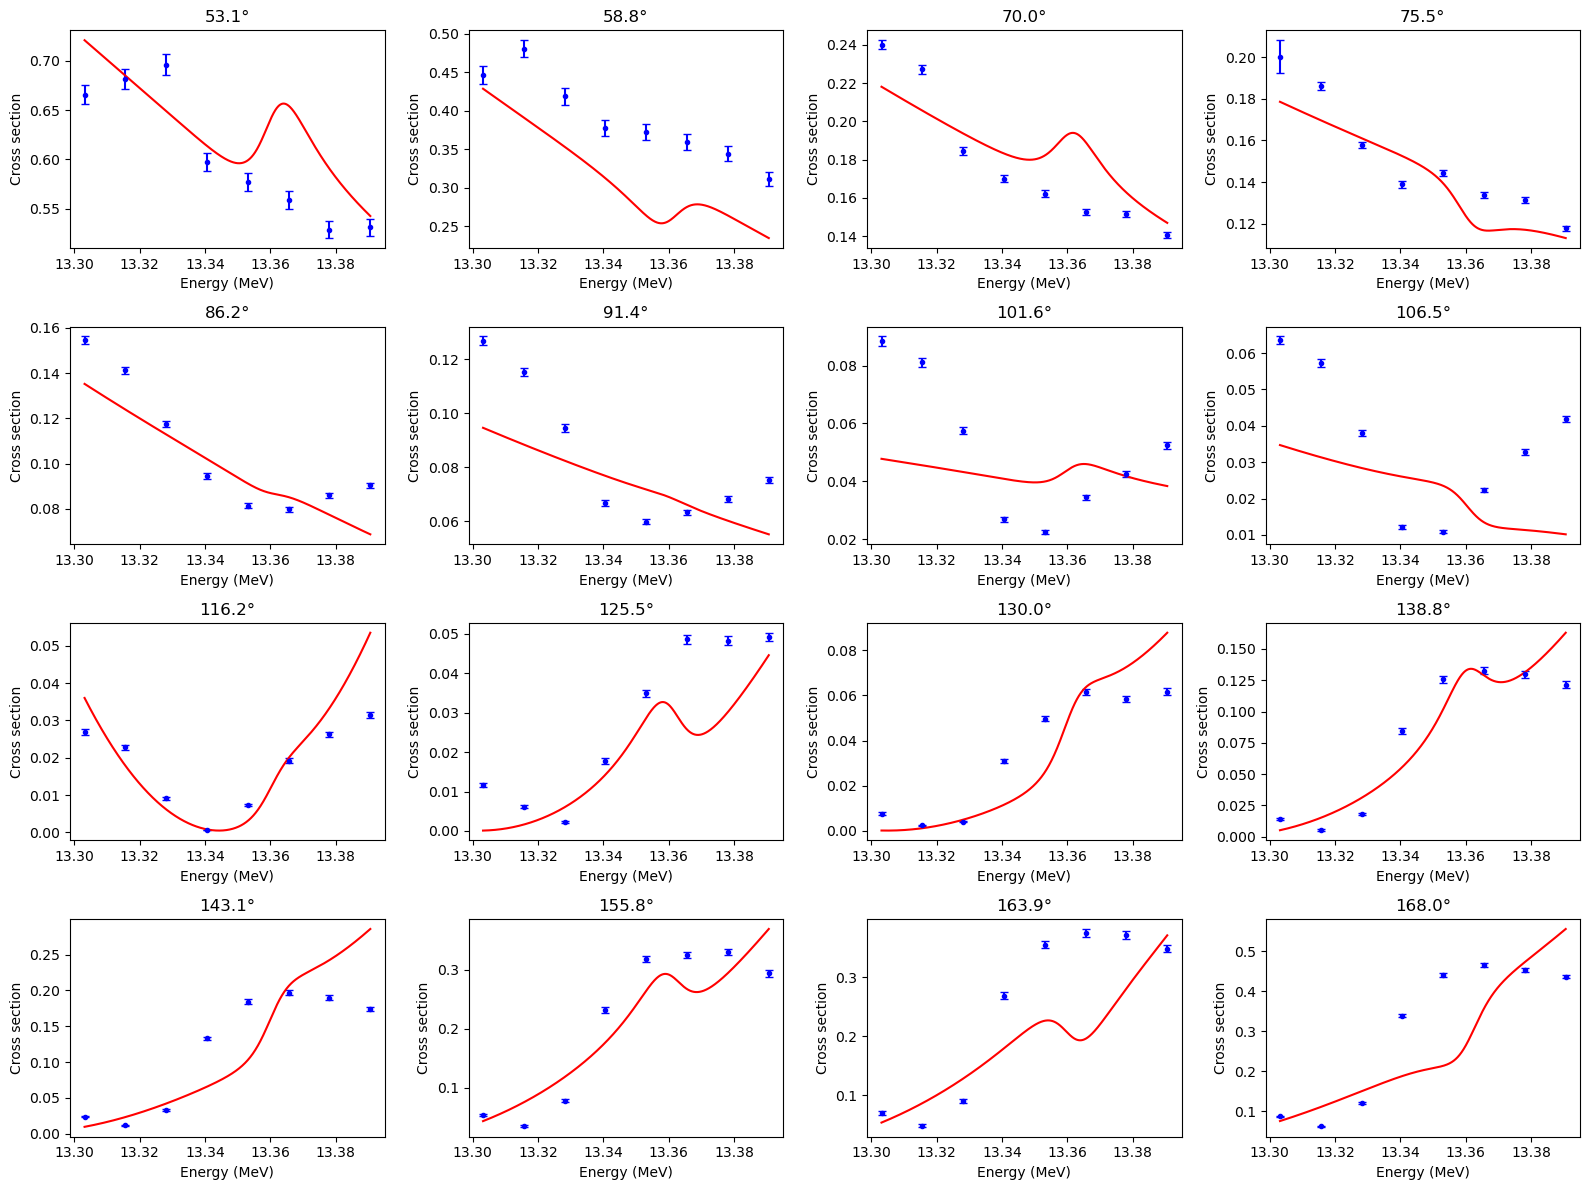

In [44]:
differential_evolution_routine.get_de_fit_visual(
    first_window, result.x, angular_momenta
)

In [ ]:
test_energies = np.append(cluster_energies, 13.41)
test_widths = np.append(cluster_widths, 0.005)

best_fit, best_bound, best_am, fits = differential_evolution_routine.de_fit_all_am(
    second_window,
    test_energies,
    m_cap=10,
    c_cap=10,
    popsize=20,
    maxiter=100
)

differential_evolution step 1: f(x)= 14734320962.036098
differential_evolution step 2: f(x)= 4985185804.523947
differential_evolution step 3: f(x)= 4985185804.523947
differential_evolution step 4: f(x)= 3340748704.579703
differential_evolution step 5: f(x)= 1245412999.2966704
differential_evolution step 6: f(x)= 1245412999.2966704
differential_evolution step 7: f(x)= 1222361790.7260294
differential_evolution step 8: f(x)= 1006912642.2296447
differential_evolution step 9: f(x)= 1006912642.2296447
differential_evolution step 10: f(x)= 724949356.3184044
differential_evolution step 11: f(x)= 351037445.4621885
differential_evolution step 12: f(x)= 235348374.56867236
differential_evolution step 13: f(x)= 180638894.76557004
differential_evolution step 14: f(x)= 134580829.20321897
differential_evolution step 15: f(x)= 134580829.20321897
differential_evolution step 16: f(x)= 130210529.70216018
differential_evolution step 17: f(x)= 130210529.70216018
differential_evolution step 18: f(x)= 3772454

In [56]:
window = first_window

angle = list(window.keys())[0]
E_min = window[angle]["E_min"]
E_max = window[angle]["E_max"]

parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

In [60]:
print(list(window.keys())[:5])

['53.1', '58.8', '70.0', '75.5', '86.2']


### Analytic - Least Squares

In [96]:
angle = list(first_window.keys())[0]

E_min = first_window[angle]["E_min"]
E_max = first_window[angle]["E_max"]

parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

In [99]:
first_window = windows[0]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(first_window, cluster_energies, cluster_widths)

with open("top_fits_w1_analytic.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, first_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w1_analytic.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 9.2319e+06, final cost 6.4743e+02, first-order optimality 1.07e+03.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.7940e+08, final cost 1.1024e+03, first-order optimality 1.89e+01.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 5.4717e+07, final cost 1.4939e+03, first-order optimality 4.23e+00.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.8600e+07, final cost 1.4061e+03, first-order optimality 1.38e+01.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 6.3284e+08, final cost 1.1933e+03, first-order optimality 8.58e+01.
Progress: 13.9% (5/36)The maxim

Resonance 1: E_r = 13.333988 MeV, l = 0, Gamma = 0.082398 MeV ratio = 0.664233
Resonance 2: E_r = 13.359647 MeV, l = 0, Gamma = 0.078462 MeV ratio = 0.484252


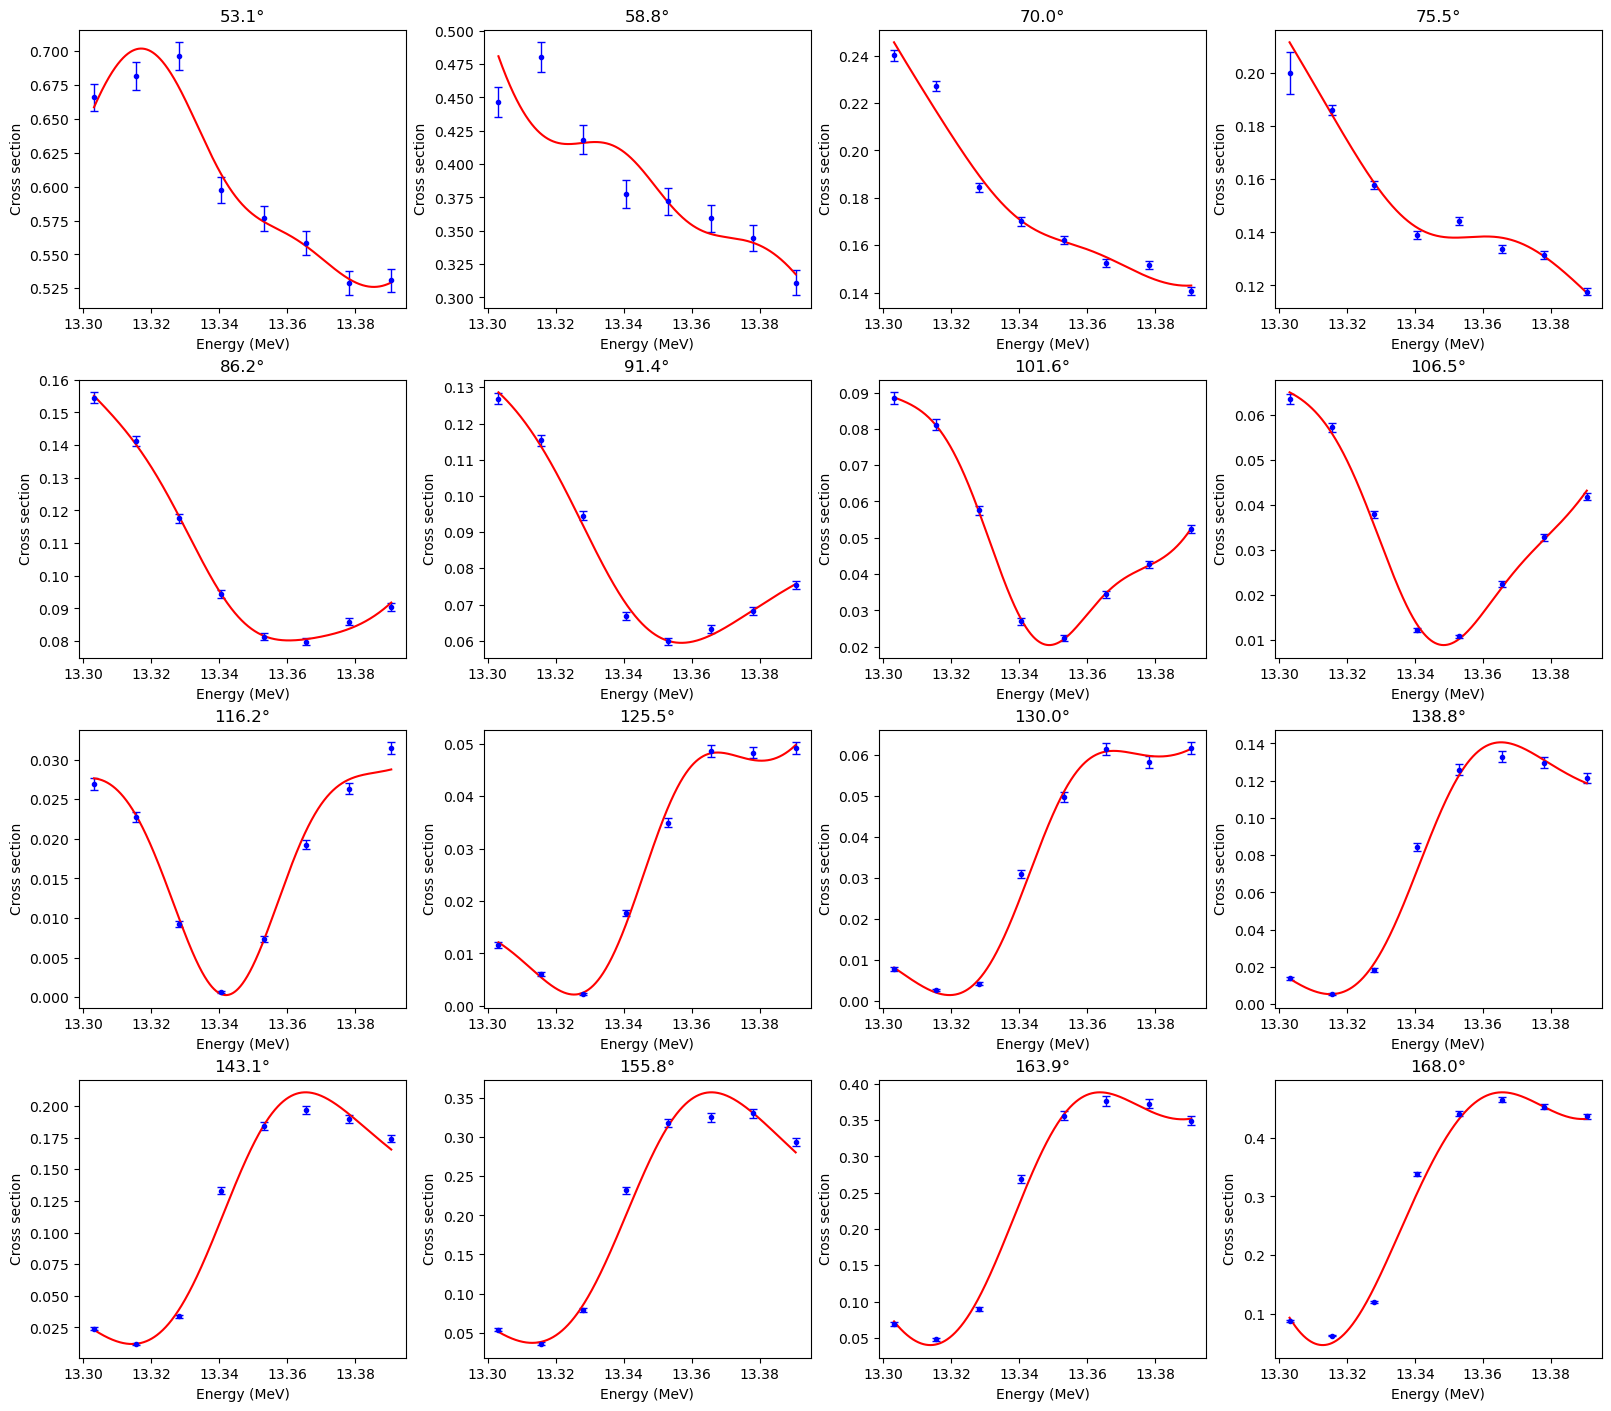

(0, 0)


In [ ]:
scattering_model.get_fit_visual(first_window, best_params, best_angular_momenta)
print(best_angular_momenta)

Initial parameters: (137,)
Lower bounds: (137,)
Upper bounds: (137,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.4165e+07, final cost 2.4054e+04, first-order optimality 3.91e+03.
Progress: 0.5% (1/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3787e+07, final cost 3.9303e+04, first-order optimality 7.75e+03.
Progress: 0.9% (2/216)Both `ftol` and `xtol` termination conditions are satisfied.
Function evaluations 76, initial cost 1.9379e+07, final cost 5.8381e+04, first-order optimality 2.26e+11.
Progress: 1.4% (3/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.8218e+07, final cost 5.0929e+04, first-order optimality 5.11e+05.
Progress: 1.9% (4/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.4005e+07, final cost 5.3105e+04, first-order optimality 3.74e+04.
Progress: 2.3% (5/216)Th

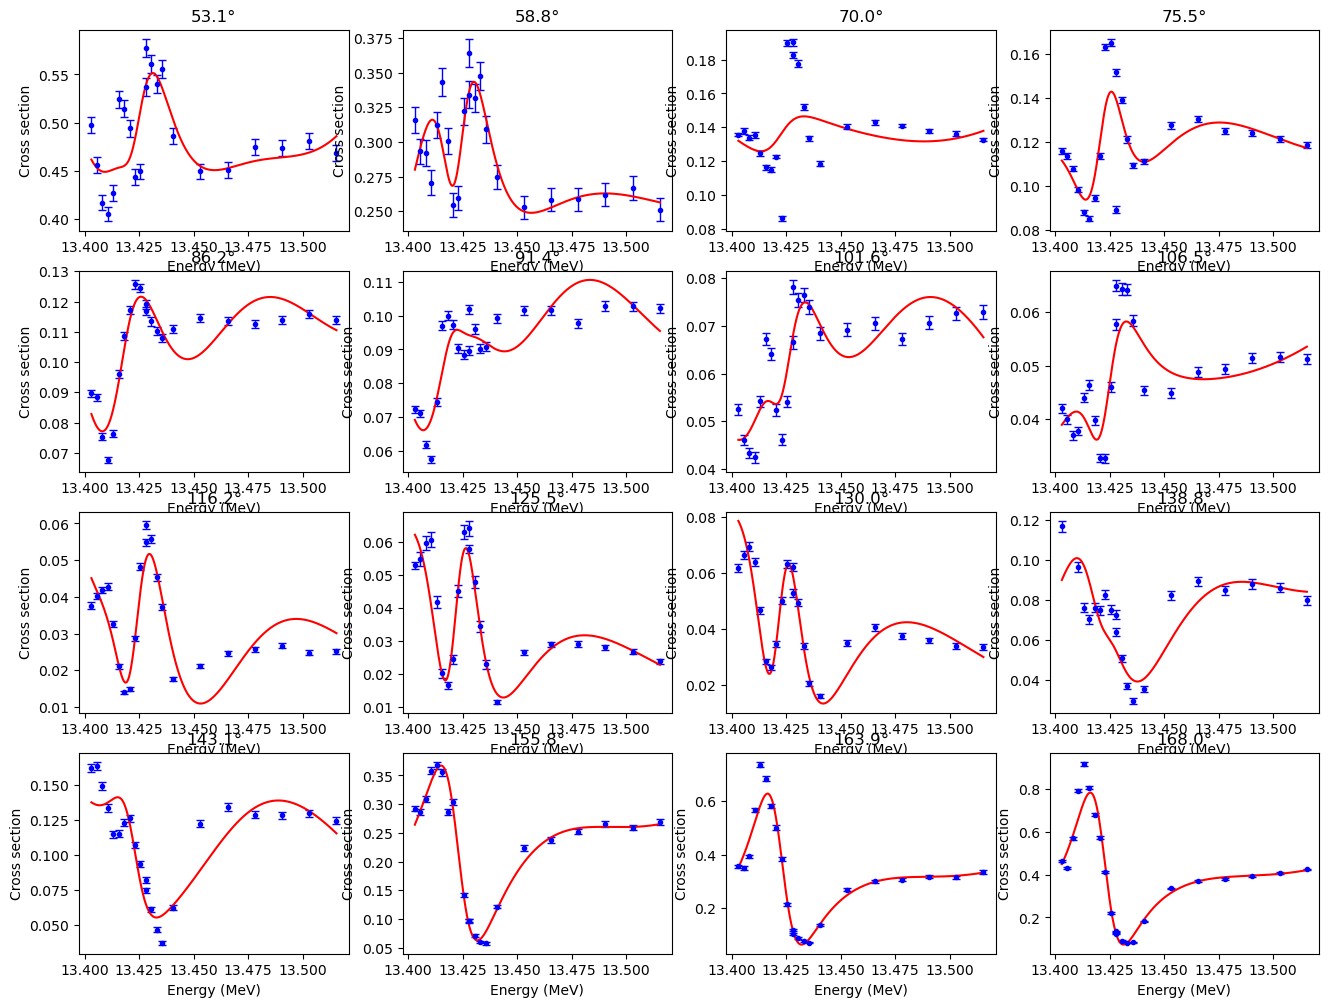

In [101]:
test_energies = np.append(cluster_energies, 13.41)
test_widths = np.append(cluster_widths, 0.005)

test_fits, test_lower_bound, test_upper_bound = scattering_model.fitting_routine_1(
    second_window,
    test_energies,
    test_widths
)

test_refined_fits = scattering_model.fitting_routine_2(test_fits, second_window, test_lower_bound, test_upper_bound)

test_best_fit_cost, test_best_angular_momenta, test_best_params = test_refined_fits[0]

scattering_model.get_fit_visual(second_window, test_best_params, test_best_angular_momenta)

In [125]:
window_clusters, boundaries = window_generation.group_resonance_energies(
    cluster_energies,
    cluster_widths,
    1
)

In [126]:
for c in window_clusters:
    print(len(c[0]))

42
3
1
1
23
4
1
1
5
2
3
6


In [119]:
for threshold in [0.25, 0.35, 0.5, 0.75, 1.0]:
    groups, boundaries = window_generation.group_resonance_energies(
        cluster_energies,
        cluster_widths,
        threshold
    )

    sizes = [len(group[0]) for group in groups]

    print(
        f"Threshold {threshold:.2f}: "
        f"{len(groups)} windows, "
        f"largest = {max(sizes)}, "
        f"windows with >3 resonances = {sum(s > 3 for s in sizes)}"
    )

Threshold 0.25: 74 windows, largest = 5, windows with >3 resonances = 1
Threshold 0.35: 62 windows, largest = 12, windows with >3 resonances = 3
Threshold 0.50: 47 windows, largest = 12, windows with >3 resonances = 5
Threshold 0.75: 24 windows, largest = 23, windows with >3 resonances = 6
Threshold 1.00: 12 windows, largest = 42, windows with >3 resonances = 5


Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.4377e+08, final cost 2.2099e+03, first-order optimality 4.51e+02.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.5644e+08, final cost 8.3346e+02, first-order optimality 6.63e+00.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.5106e+08, final cost 5.1806e+02, first-order optimality 2.46e+02.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.5829e+08, final cost 1.7917e+03, first-order optimality 4.15e+02.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.6039e+08, final cost 1.3288e+03, first-order optimality 1.22e+01.
Progress: 13.9% (5/36)The maxim

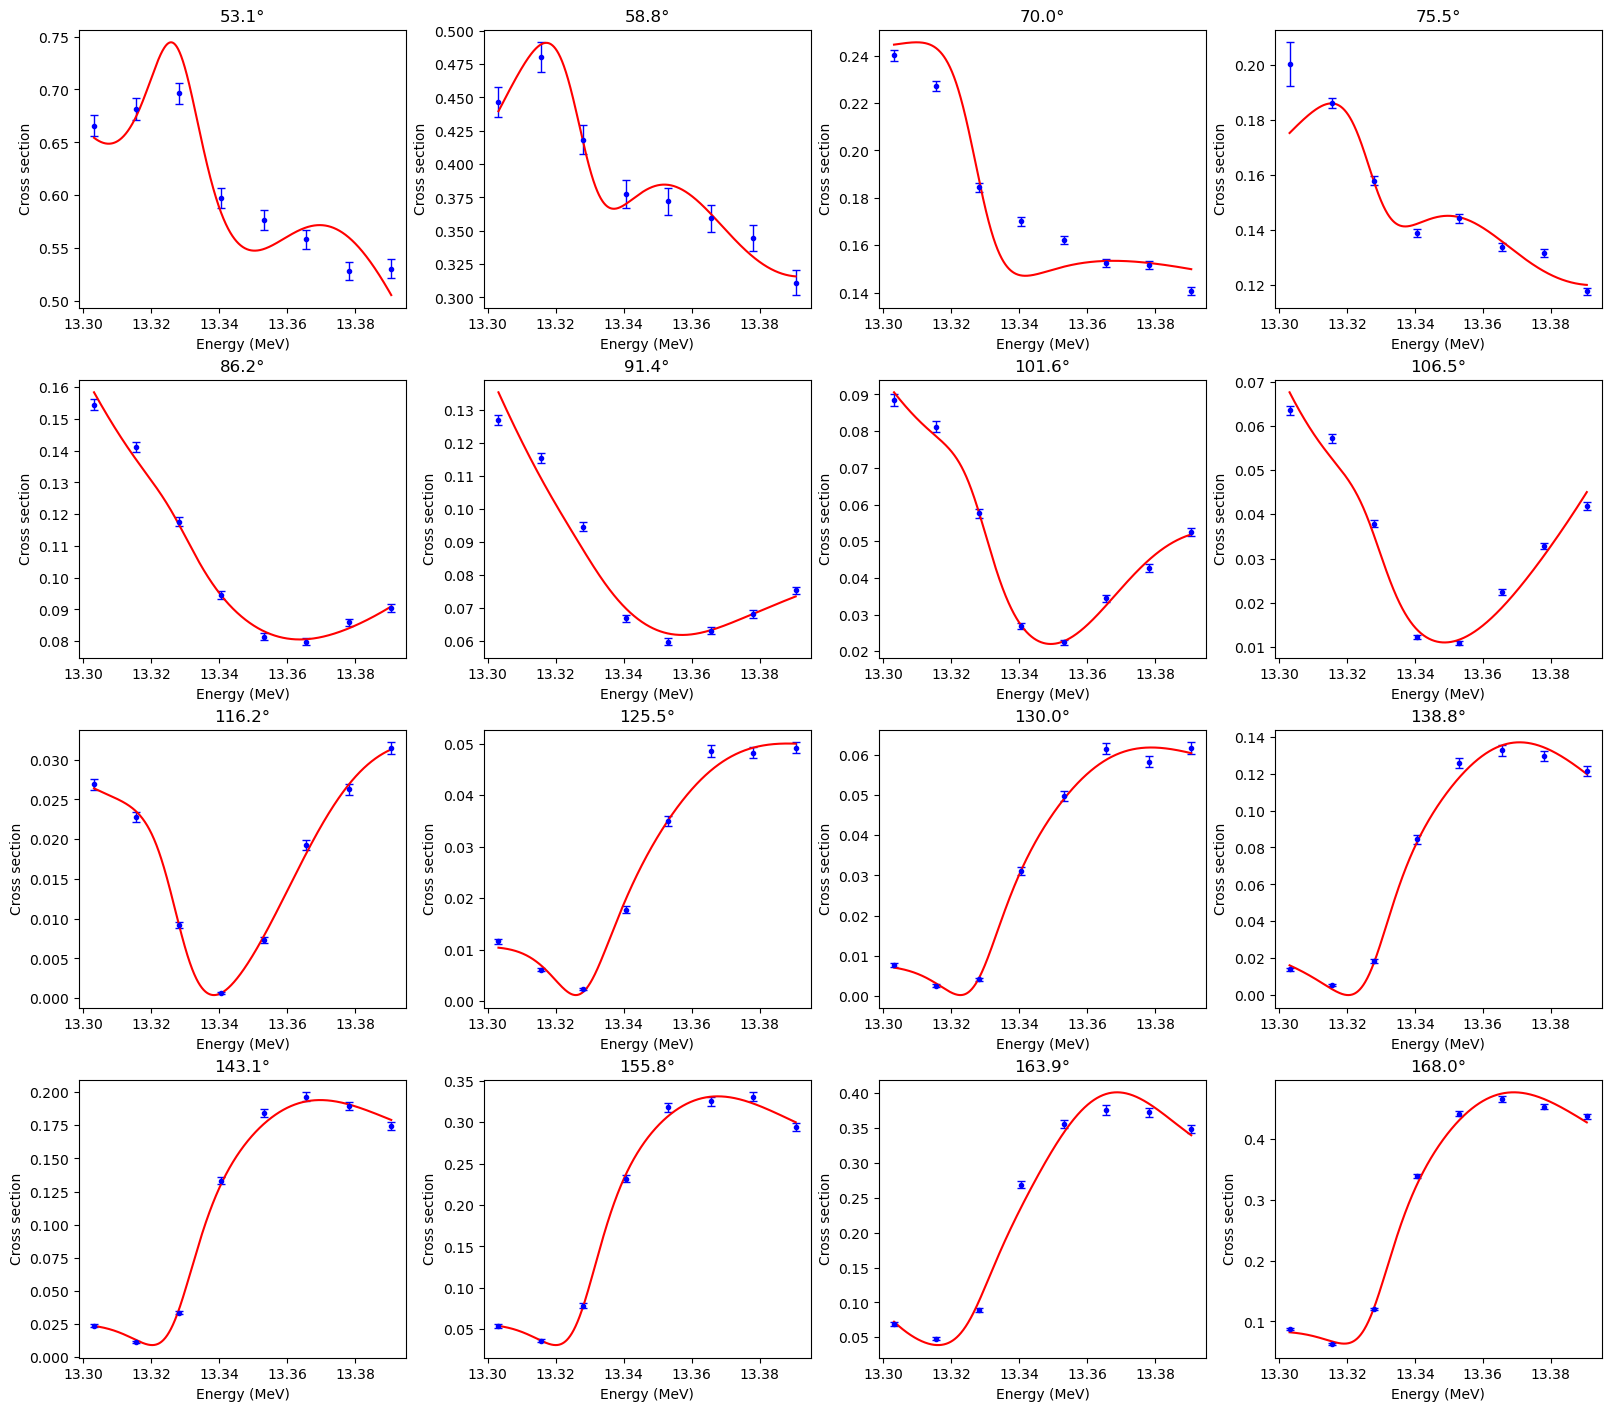

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 5.5158e+07, final cost 2.7259e+04, first-order optimality 1.15e+03.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.7242e+07, final cost 3.3184e+04, first-order optimality 1.40e+02.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 7.0227e+07, final cost 2.9085e+04, first-order optimality 6.97e+01.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.7630e+08, final cost 2.5715e+04, first-order optimality 4.79e+02.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.9849e+08, final cost 3.0892e+04, first-order optimality 4.57e+02.
Progress: 13.9% (5/36)The maxim

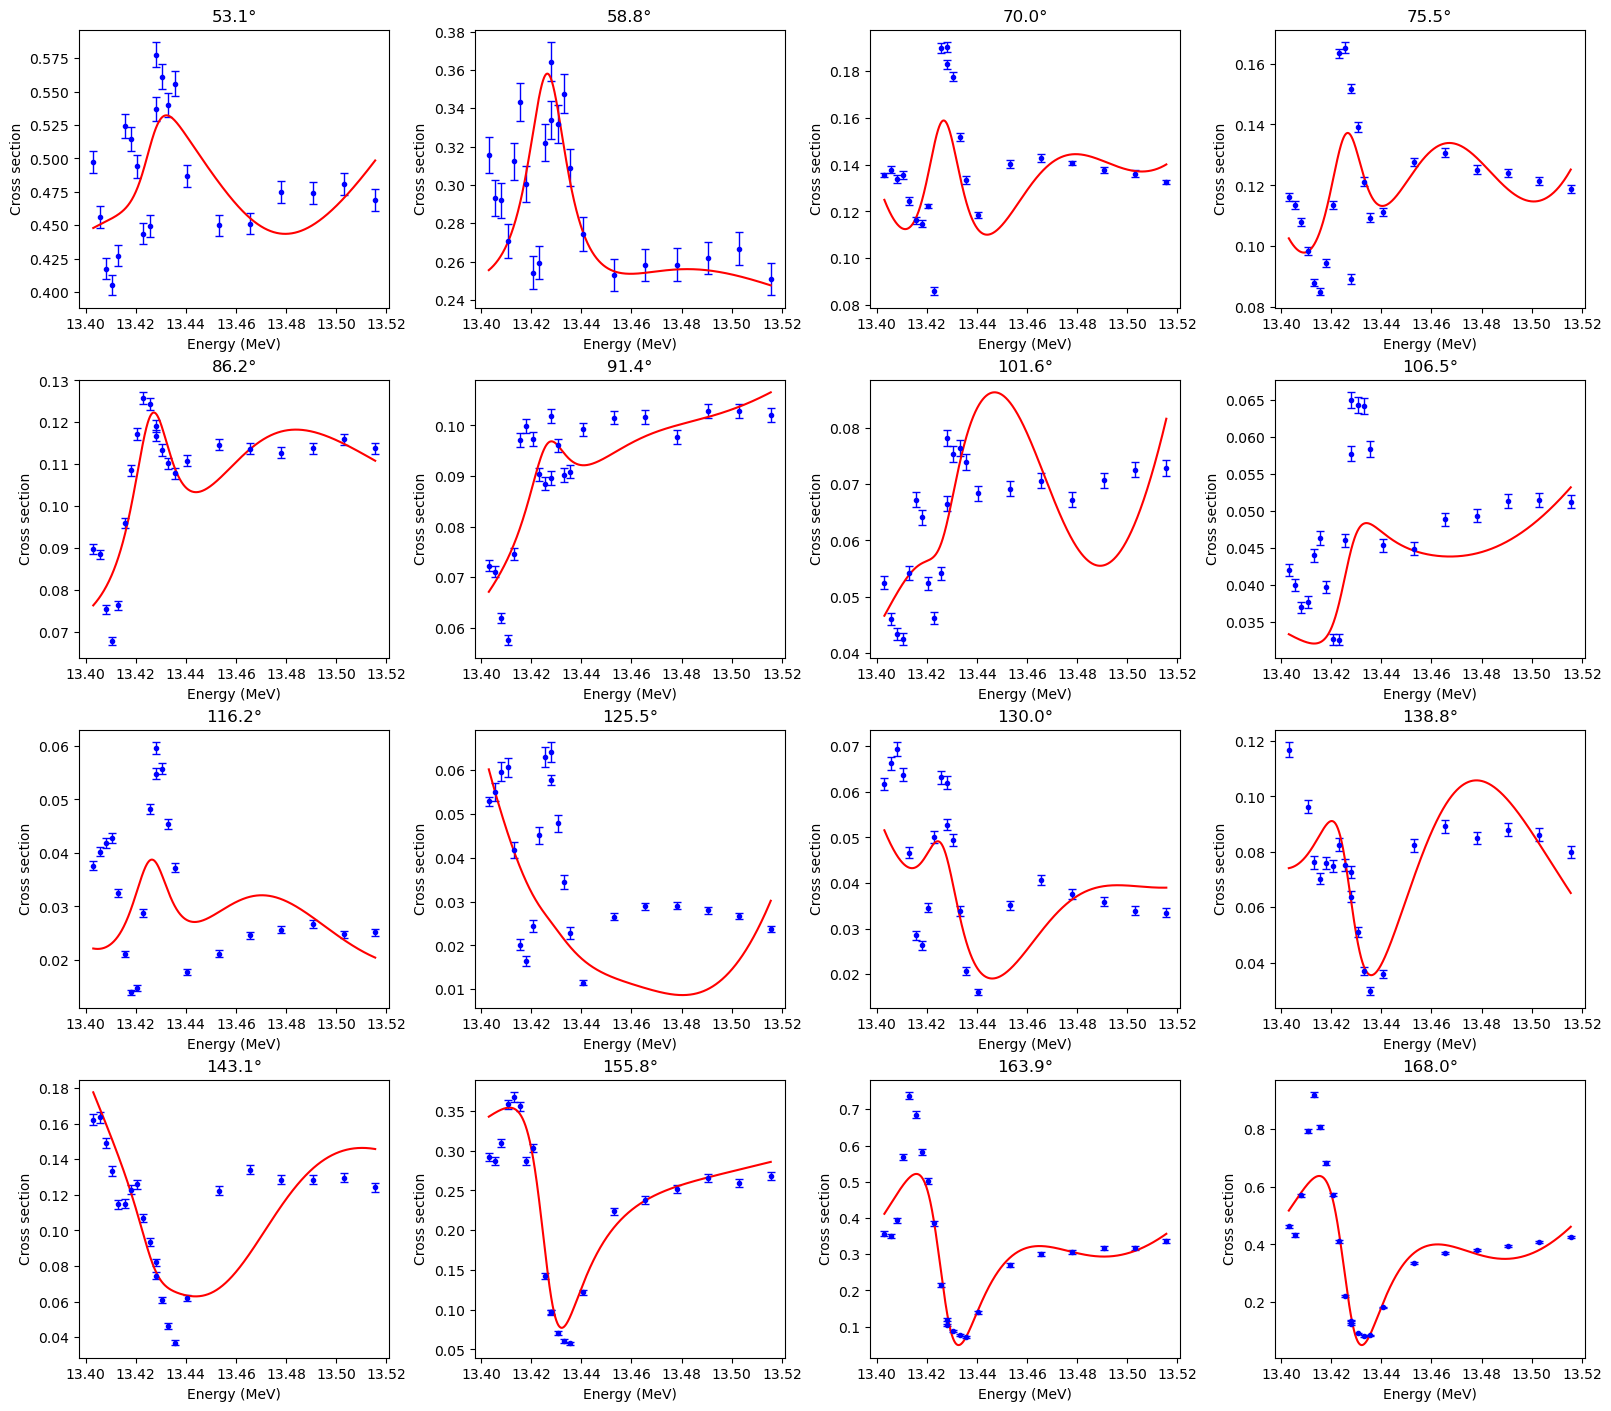

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3984e+07, final cost 1.5394e+03, first-order optimality 1.97e+00.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.6599e+08, final cost 2.2517e+03, first-order optimality 1.27e+02.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.0773e+08, final cost 1.3946e+03, first-order optimality 1.17e+03.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.6937e+08, final cost 9.1840e+03, first-order optimality 2.70e+04.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 6.4155e+08, final cost 1.5444e+03, first-order optimality 6.63e+02.
Progress: 13.9% (5/36)The maxim

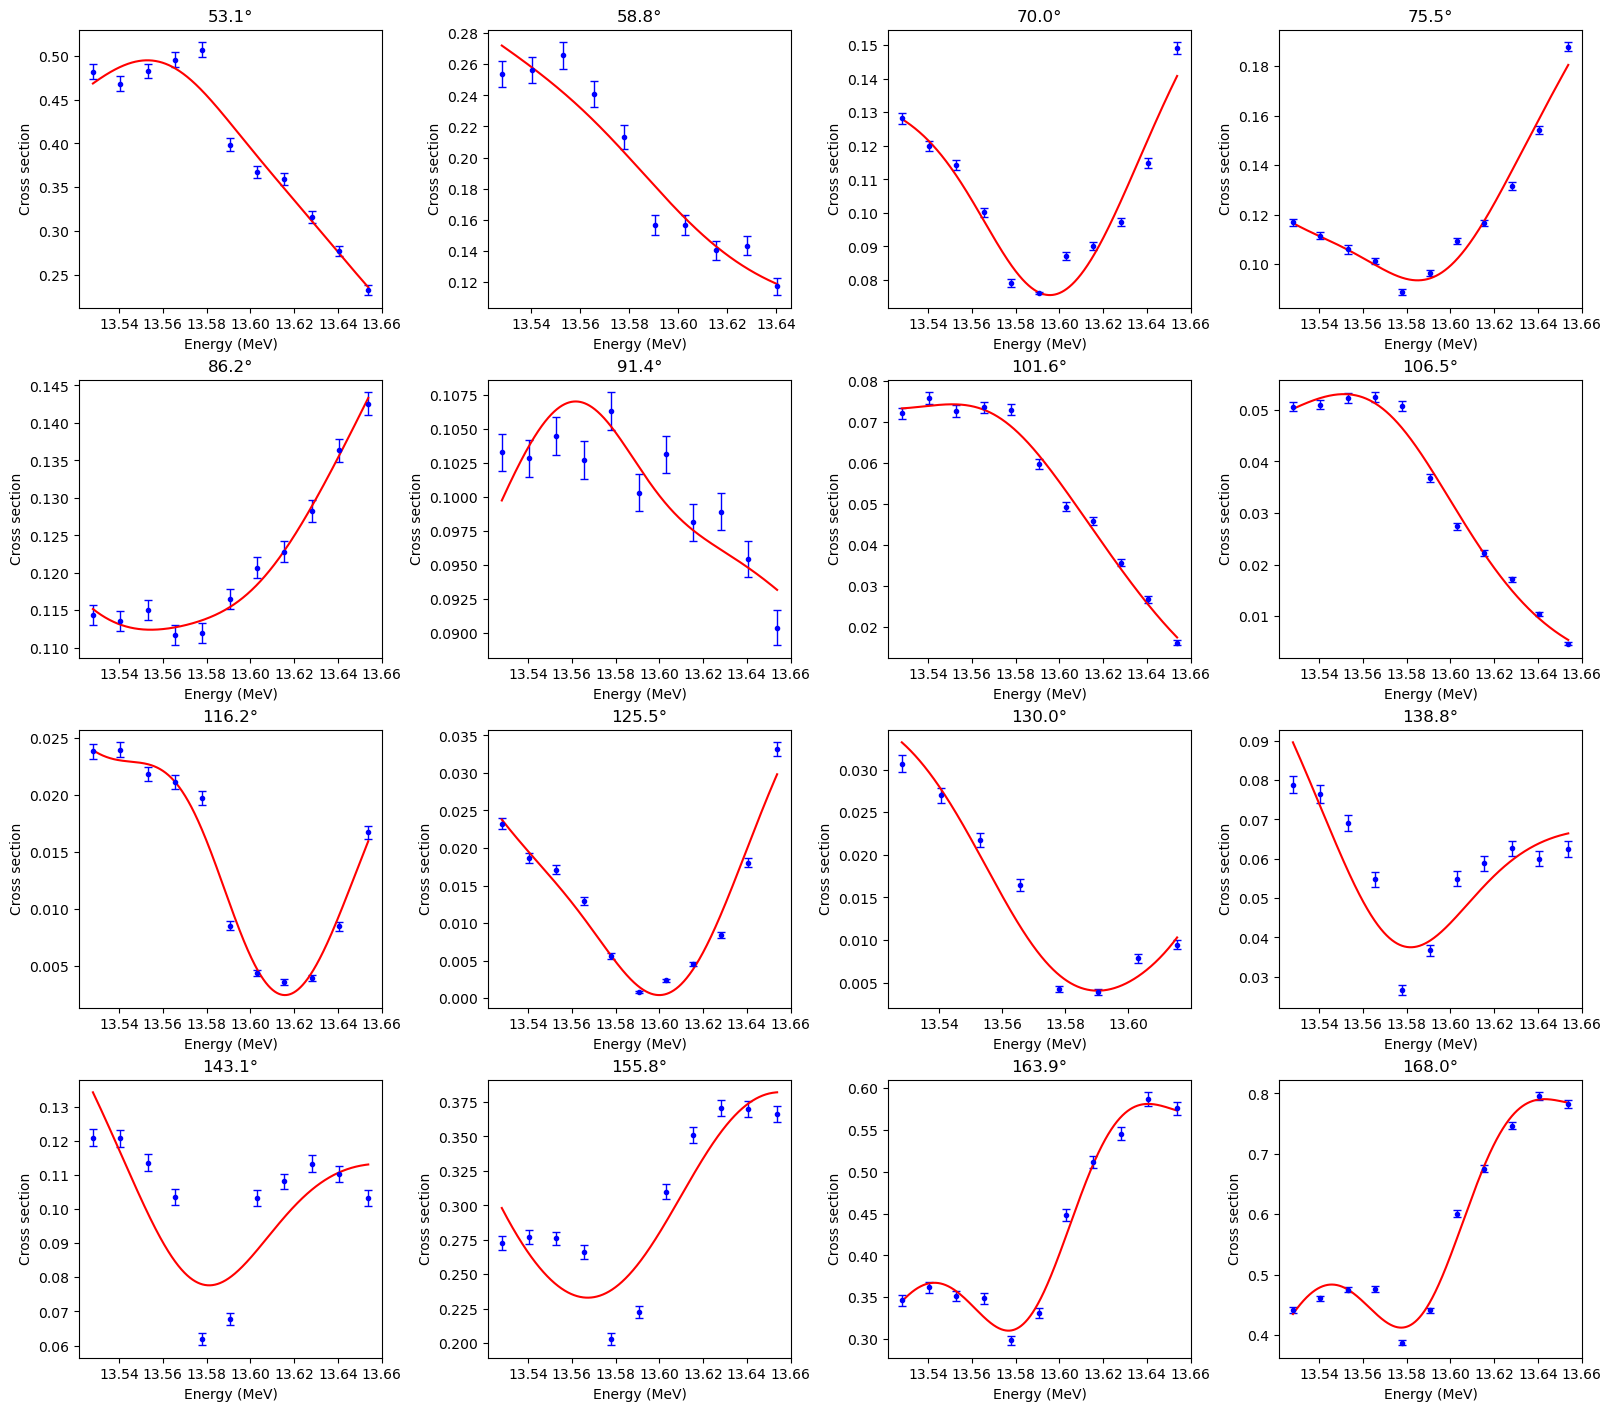

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.6699e+07, final cost 4.8448e+03, first-order optimality 3.26e+02.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 5.7735e+07, final cost 4.0570e+03, first-order optimality 1.92e+02.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.0463e+08, final cost 4.4271e+03, first-order optimality 4.05e+01.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.8926e+08, final cost 4.5299e+03, first-order optimality 2.07e+02.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.0627e+08, final cost 3.4116e+03, first-order optimality 1.22e+02.
Progress: 13.9% (5/36)The maxim

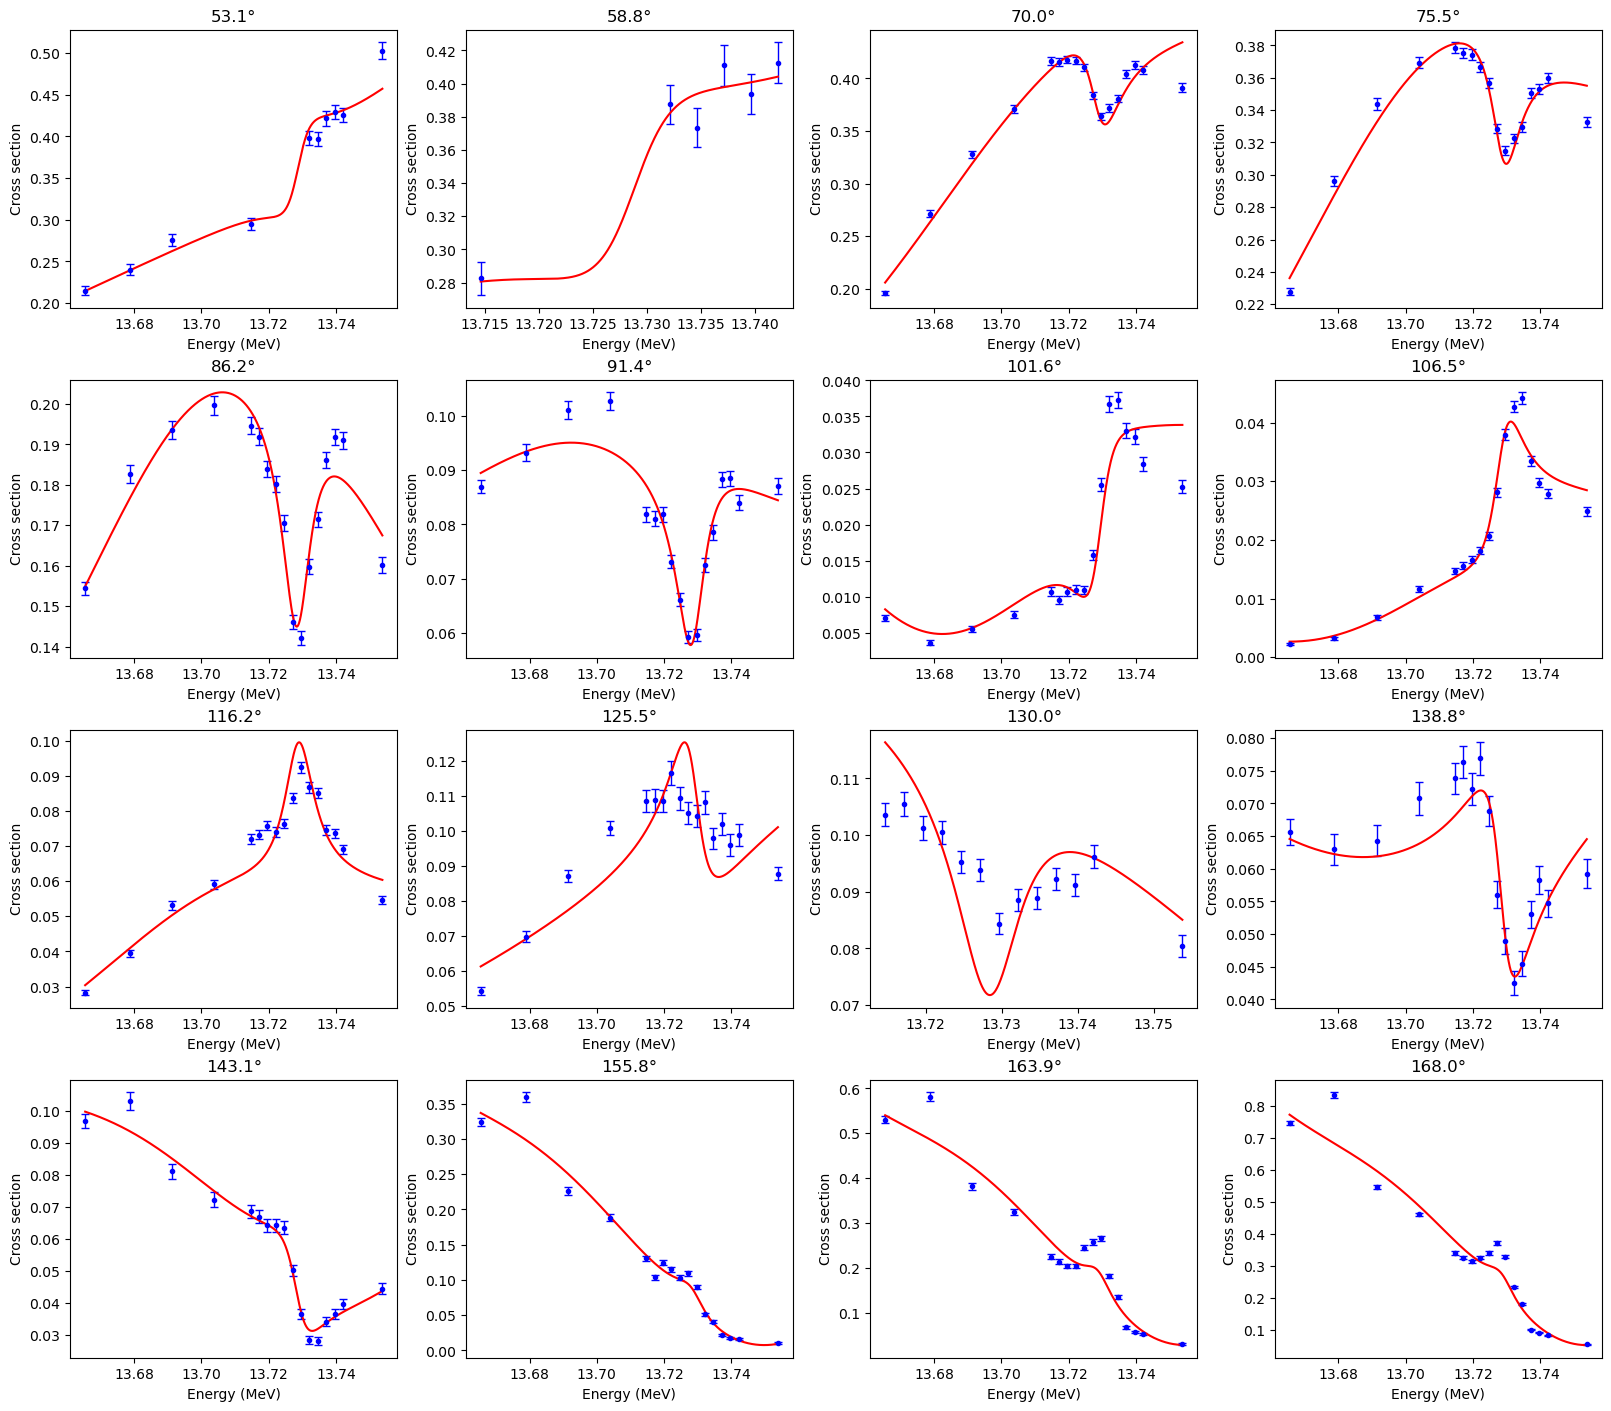

Initial parameters: (67,)
Lower bounds: (67,)
Upper bounds: (67,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.7150e+06, final cost 1.2316e+03, first-order optimality 1.78e+01.
Progress: 16.7% (1/6)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.8084e+07, final cost 1.4267e+02, first-order optimality 1.30e+02.
Progress: 33.3% (2/6)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 7.6697e+07, final cost 3.5466e+05, first-order optimality 5.42e+04.
Progress: 50.0% (3/6)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.4051e+08, final cost 9.2671e+04, first-order optimality 5.95e+03.
Progress: 66.7% (4/6)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.7949e+08, final cost 2.0524e+01, first-order optimality 1.67e+02.
Progress: 83.3% (5/6)The maximum nu

ValueError: zero-size array to reduction operation minimum which has no identity

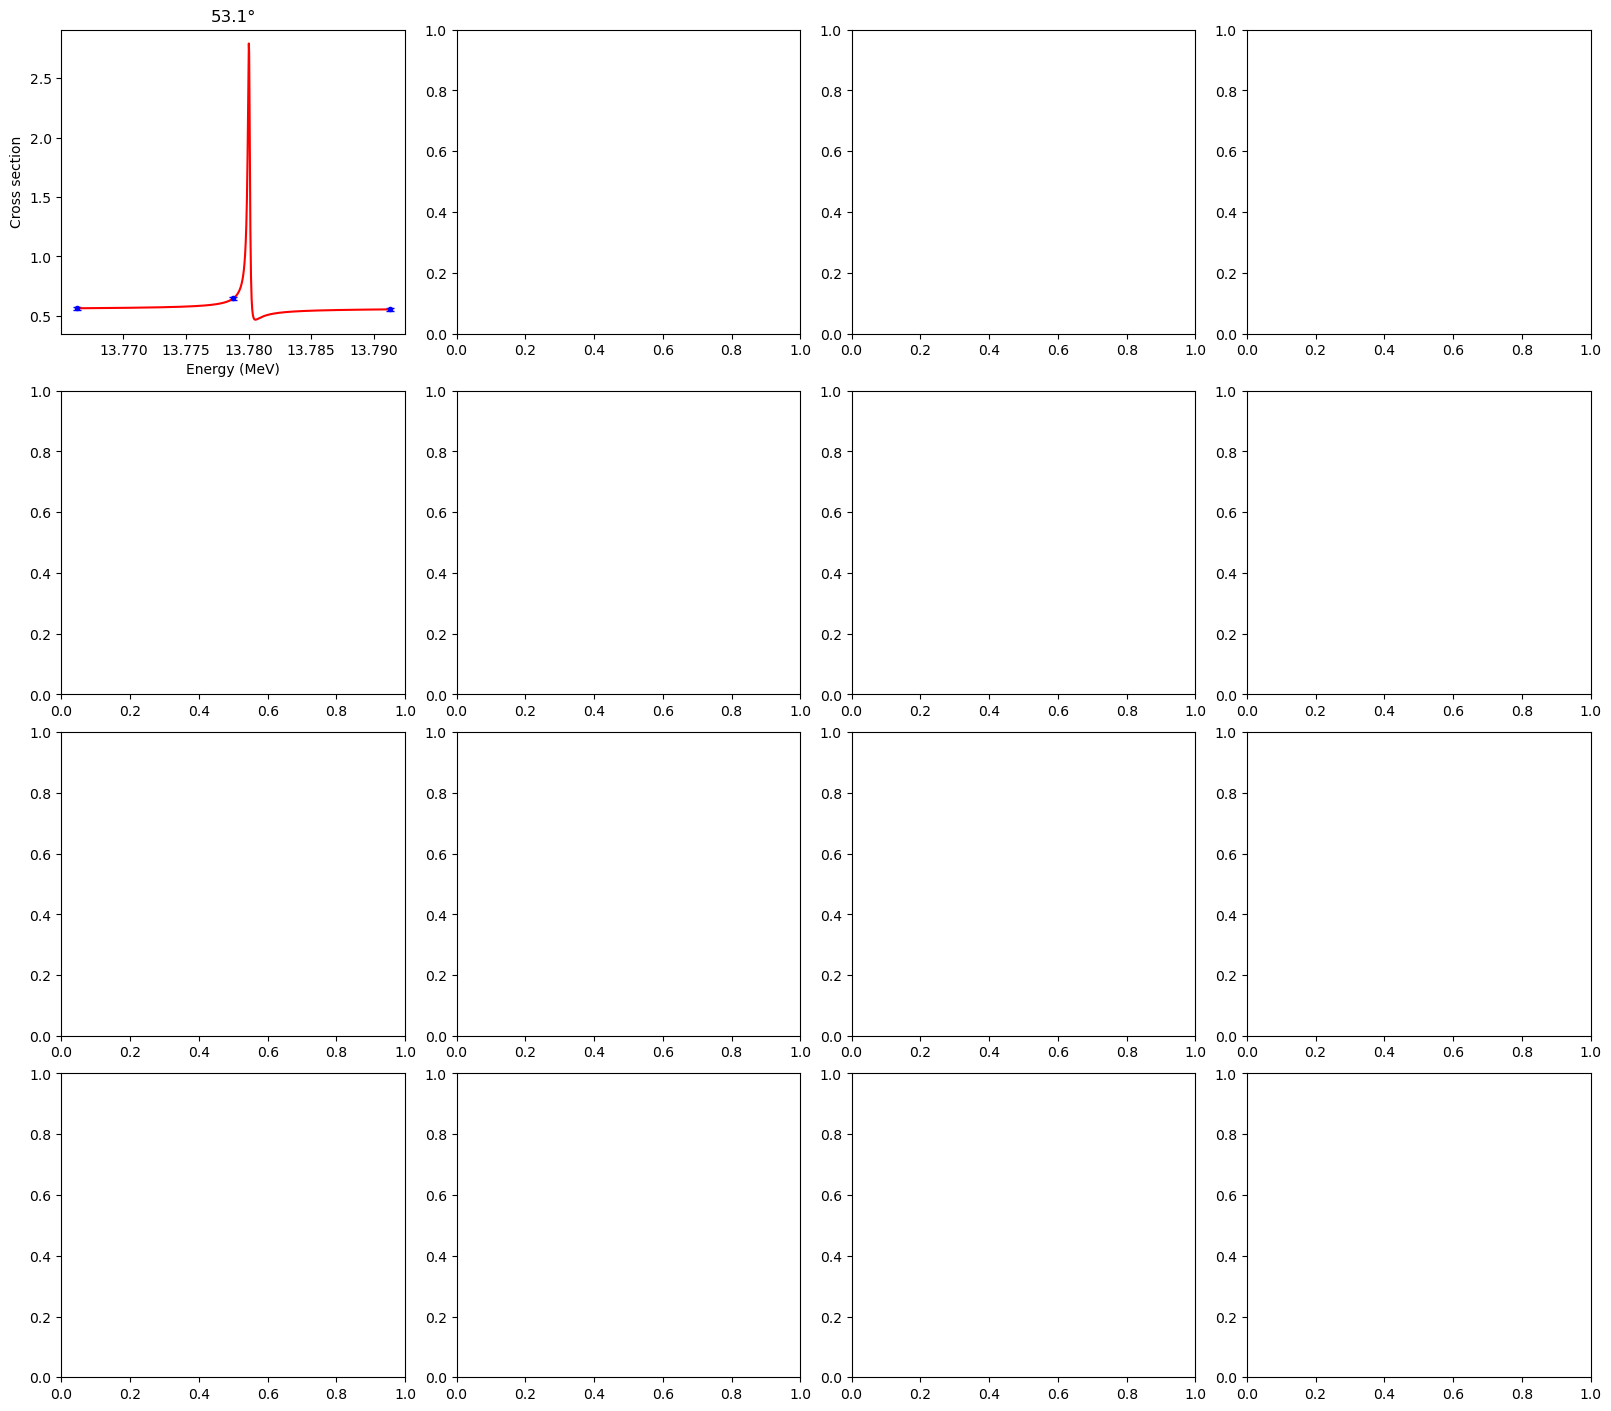

In [128]:
windows = scattering_model.get_windows(all_cs, clusters)

results = []

for i, window in enumerate(windows):
    fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(window, cluster_energies, cluster_widths)

    refined_fits = scattering_model.fitting_routine_2(fits, window, lower_bound, upper_bound)

    best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

    results.append({
        "window_number": i,
        "window": window,
        "cost": best_fit_cost,
        "am": best_angular_momenta,
        "params": best_params
    })

    scattering_model.get_fit_visual(window, best_params, best_angular_momenta)